In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import  mean_squared_error ,r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split


data=pd.read_csv(r"C:\Users\Adithyan\Downloads\medical_insurance.csv")
print(data.head())
print(data.describe(include="all").T)
print(data.info())

   age  insurance_cost
0   58           66968
1   19            8904
2   33           23476
3   26           14707
4   61           75531
                 count       mean           std     min      25%      50%  \
age             1000.0     41.680     13.696247    18.0     30.0     41.0   
insurance_cost  1000.0  40181.709  22545.788243  7374.0  20676.5  36115.0   

                    75%      max  
age                54.0     65.0  
insurance_cost  59015.0  85702.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             1000 non-null   int64
 1   insurance_cost  1000 non-null   int64
dtypes: int64(2)
memory usage: 15.8 KB
None


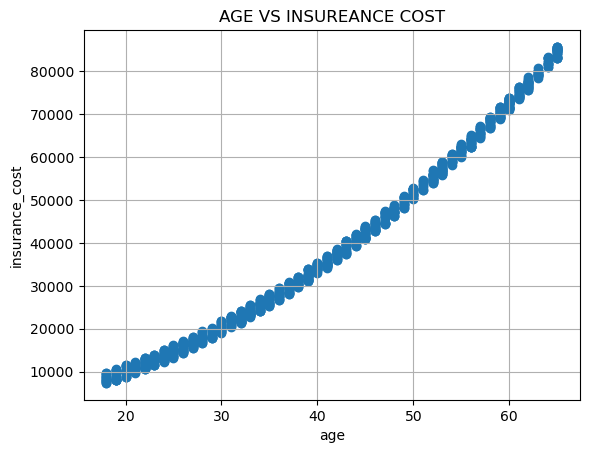

In [6]:
plt.scatter(data["age"],data["insurance_cost"])
plt.title("AGE VS INSUREANCE COST")
plt.xlabel("age")
plt.ylabel("insurance_cost")
plt.grid()
plt.show()

In [18]:
X=data[["age"]]
y=data["insurance_cost"]

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

y_test_pred = model.predict(X_test_poly)
y_train_pred = model.predict(X_train_poly)
print("actual test score:",y_test)
print("prediction score:",y_train)

print("MSE:", mean_squared_error(y_test, y_test_pred))
print("R2 Score:", r2_score(y_test, y_test_pred))

prediction = model.predict(poly.transform([[45]]))
print("Predicted insurance cost:",prediction[0])

actual test score: 521    54832
737    24047
740    70207
660    30699
411    43559
       ...  
408    62663
332    18416
208    13688
613    16345
78     76250
Name: insurance_cost, Length: 200, dtype: int64
prediction score: 29     69045
535    42170
695    47440
557    44762
836    32495
       ...  
106    26049
270    19843
860    34360
435    33658
102    12533
Name: insurance_cost, Length: 800, dtype: int64
MSE: 697540.5479784147
R2 Score: 0.9987089719605757
Predicted insurance cost: 42332.35493177644


C:\Users\Adithyan\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
